In [2]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../Dataset/telco_clean.csv")

Plot the distribution of customer tenure


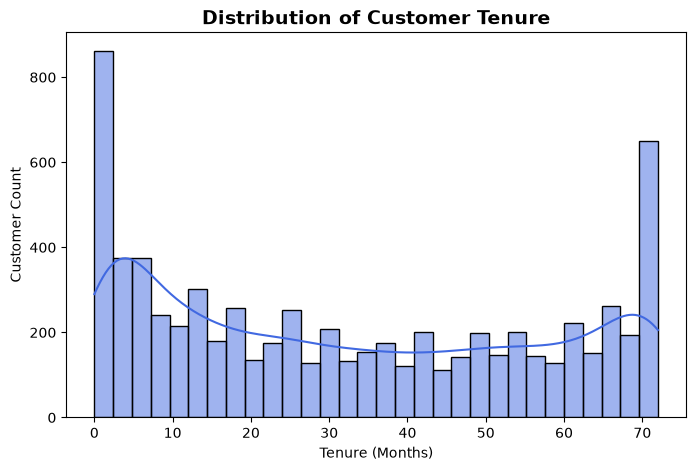

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tenure", kde=True, bins=30, color="royalblue")

plt.title("Distribution of Customer Tenure", fontsize=14, fontweight="bold")
plt.xlabel("Tenure (Months)")
plt.ylabel("Customer Count")
plt.show()

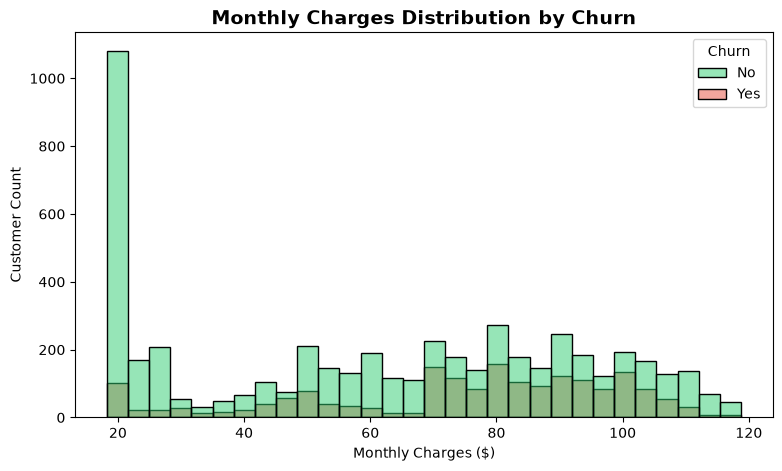

In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}
)

plt.title("Monthly Charges Distribution by Churn",
          fontsize=14, fontweight="bold")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Customer Count")
plt.show()

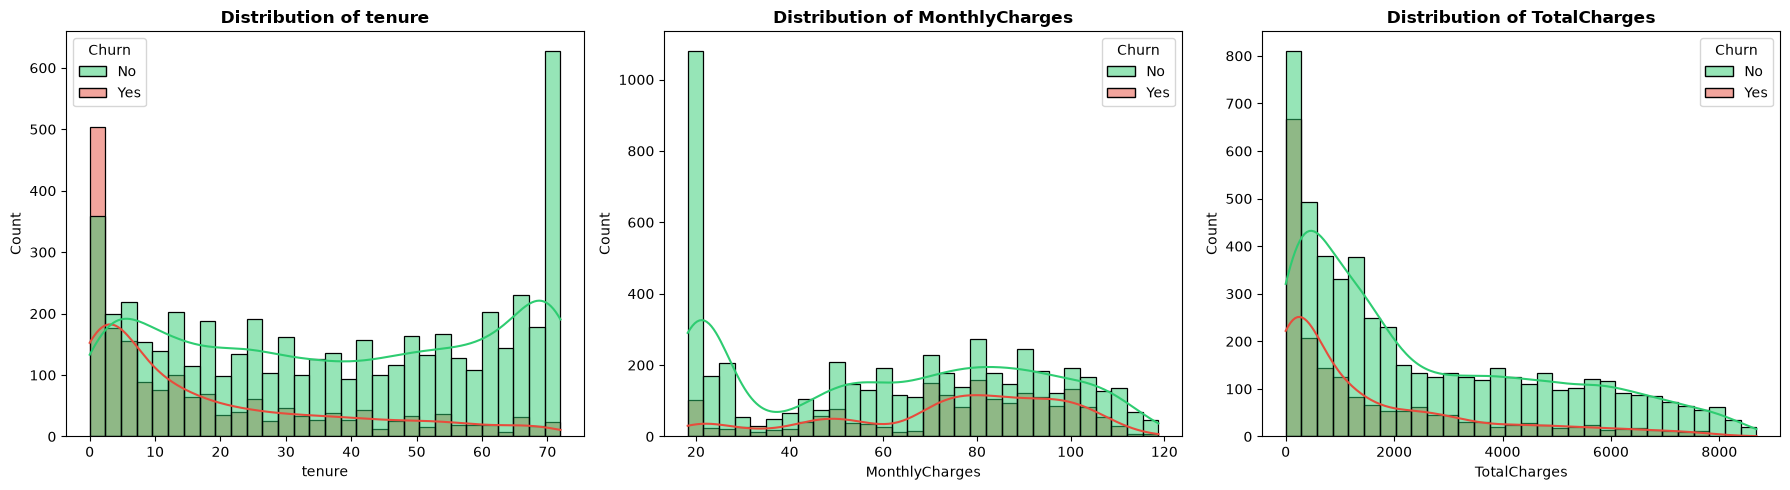

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Churn",
        kde=True,
        bins=30,
        ax=ax,
        palette={"No": "#2ecc71", "Yes": "#e74c3c"}
    )
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_22348\3145742232.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_22348\3145742232.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_22348\3145742232.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


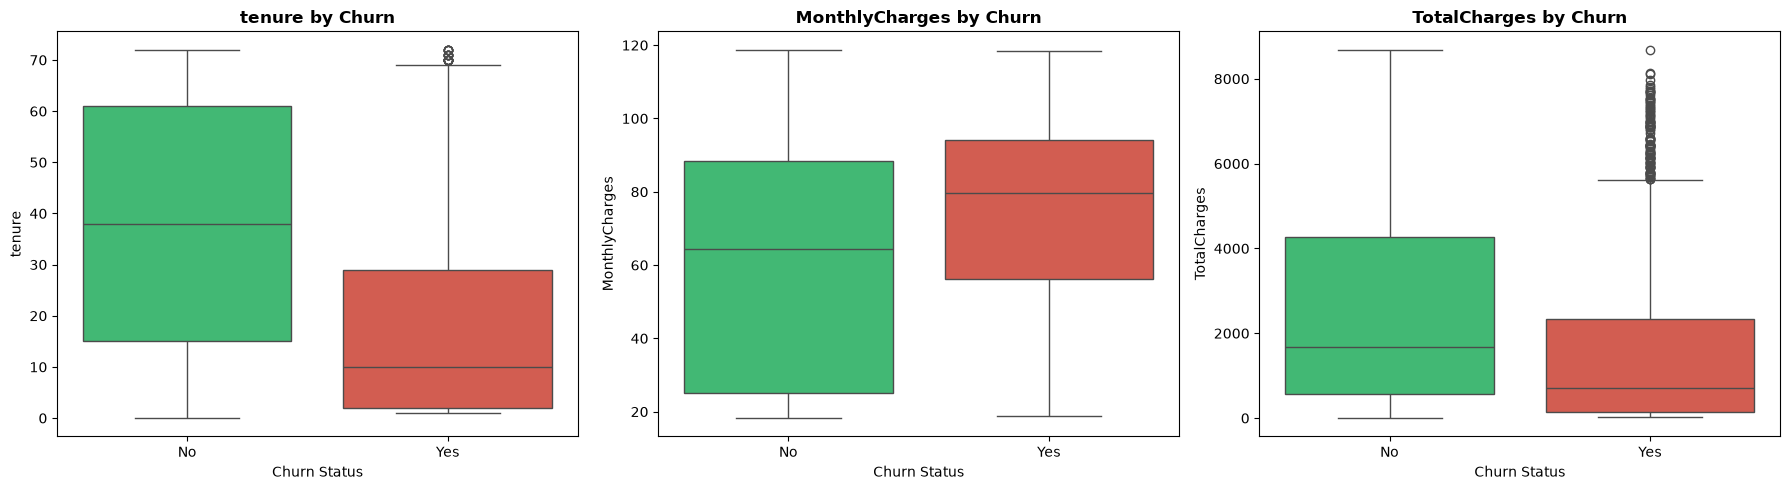

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, num_cols):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        ax=ax,
        palette={"No": "#2ecc71", "Yes": "#e74c3c"}
    )
    ax.set_title(f"{col} by Churn", fontsize=12, fontweight="bold")
    ax.set_xlabel("Churn Status")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

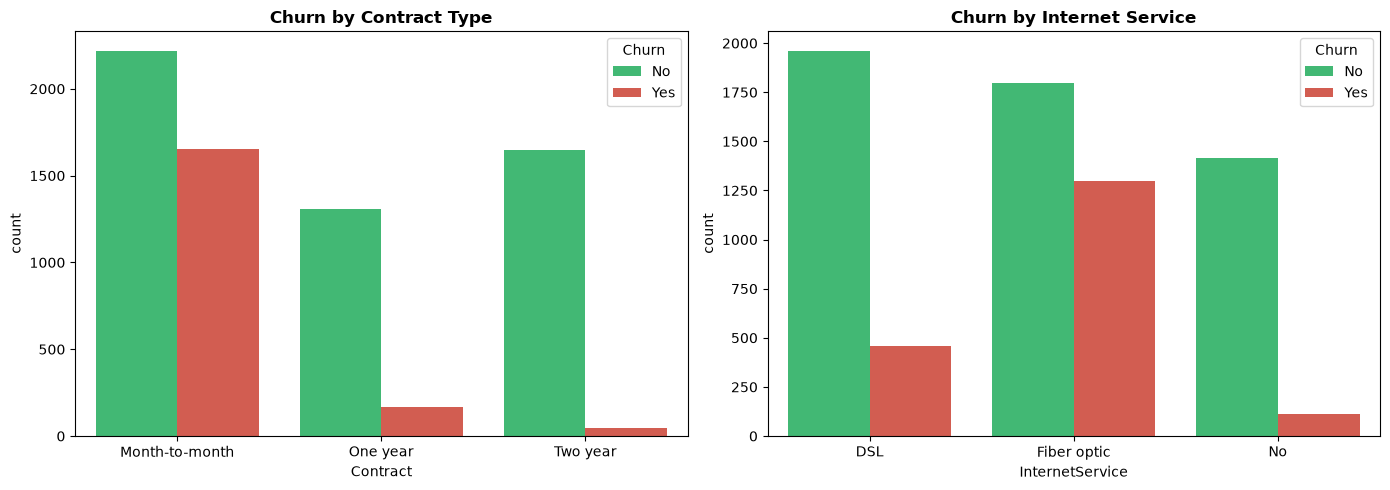

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Churn by Contract
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    ax=axes[0],
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}
)
axes[0].set_title("Churn by Contract Type", fontsize=12, fontweight="bold")

# Churn by Internet Service
sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    ax=axes[1],
    palette={"No": "#2ecc71", "Yes": "#e74c3c"}
)
axes[1].set_title("Churn by Internet Service", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

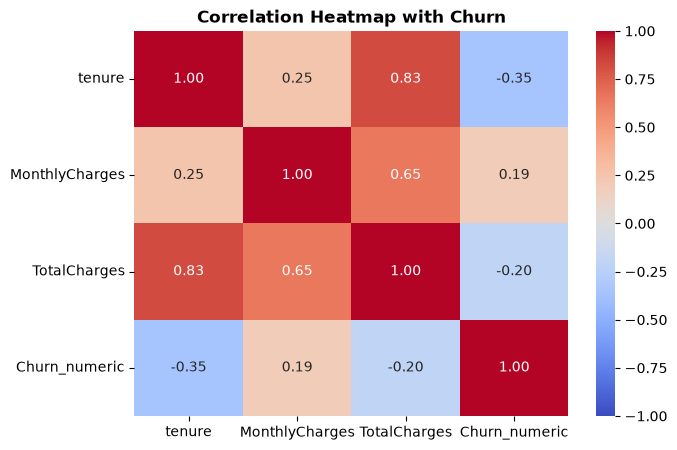

In [10]:
# Create numeric churn flag for correlation
df["Churn_numeric"] = df["Churn"].map({"Yes": 1, "No": 0})

plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_numeric"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap with Churn", fontsize=12, fontweight="bold")
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_22348\2873849361.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette={"No": "#2ecc71", "Yes": "#e74c3c"})


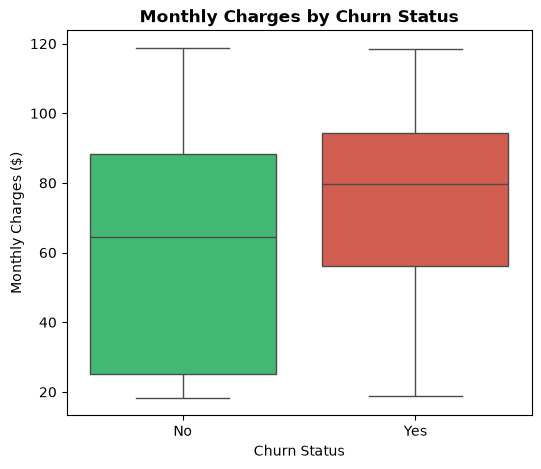

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges",
            palette={"No": "#2ecc71", "Yes": "#e74c3c"})
plt.title("Monthly Charges by Churn Status", fontsize=12, fontweight="bold")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_22348\2282952232.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="tenure", palette={"No": "#2ecc71", "Yes": "#e74c3c"})


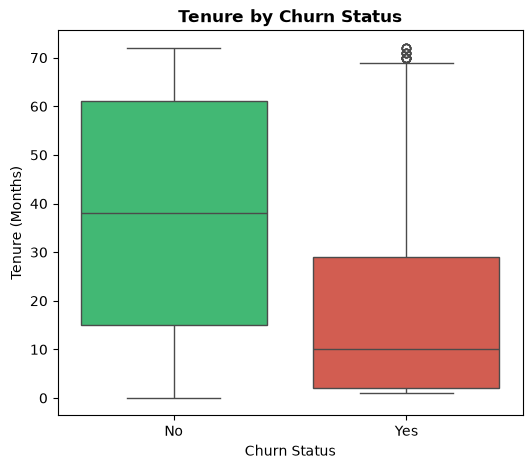

In [ ]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="Churn", y="tenure", palette={
            "No": "#2ecc71", "Yes": "#e74c3c"})
plt.title("Tenure by Churn Status", fontsize=12, fontweight="bold")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

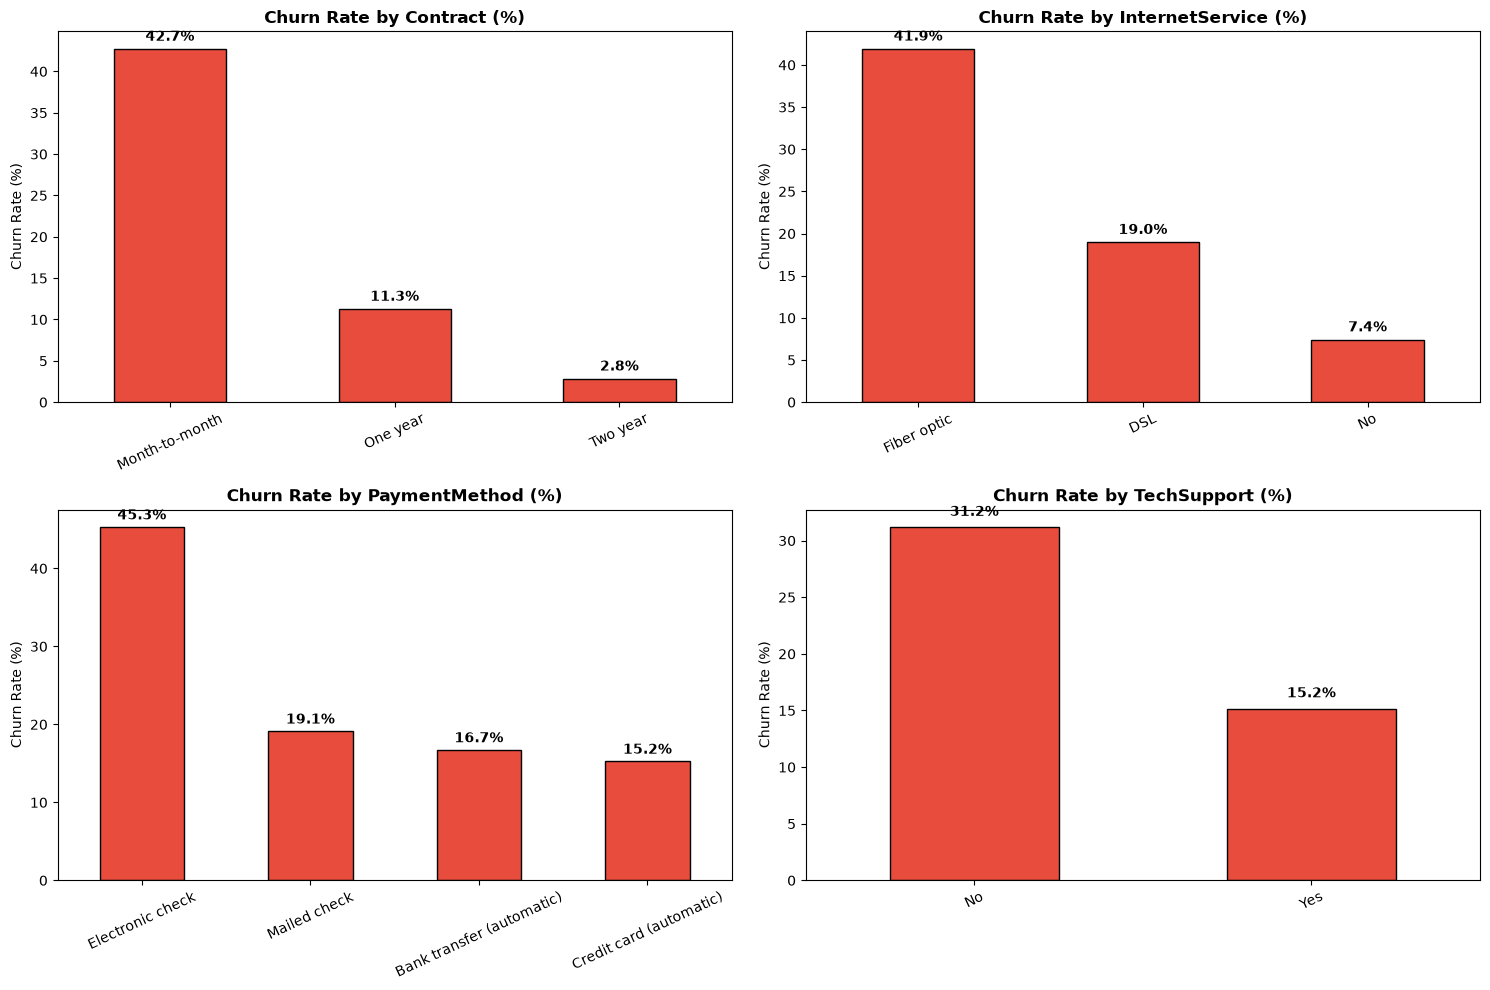

In [14]:
key_cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flatten(), key_cats):
    # Calculate churn percentage for each group
    churn_rate = (
        df.groupby(col)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )
    churn_rate.plot(kind="bar", ax=ax, color="#e74c3c", edgecolor="black")
    ax.set_title(f"Churn Rate by {col} (%)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

    # Add percentage labels
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height() + 1),
            ha="center", fontsize=10, fontweight="bold"
        )
plt.tight_layout()
plt.show()

In [21]:
# 0-6 months churn rate

rate_6_month = (df[df["tenure"] <= 6]["Churn"] == 'Yes').mean()*100
print(f"0---6 months churn rate: {rate_6_month:.2f}%")

# 0 - 12 months churn rate
rate_12_month = (df[df["tenure"] <= 12]["Churn"] == 'Yes').mean()*100
print(f"0---12 months churn rate: {rate_12_month:.2f}%")

# more than 60 months churn rate
rate_60_month = (df[df["tenure"] > 60]["Churn"] == 'Yes').mean()*100
print(f"0---12 months churn rate: {rate_60_month:.2f}%")

0---6 months churn rate: 52.94%
0---12 months churn rate: 47.44%
0---12 months churn rate: 6.61%


tenure_cohort
0-6m      52.94
7-12m     35.89
13-24m    28.71
25-36m    21.63
37-48m    19.03
49-60m    14.42
61-72m     6.61
Name: Churn, dtype: float64


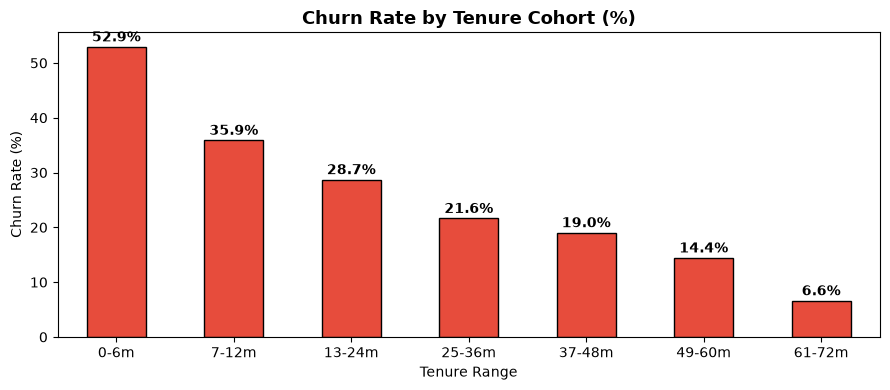

In [ ]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ['0-6m', '7-12m', '13-24m', '25-36m', '37-48m', '49-60m', '61-72m']

df['tenure_cohort'] = pd.cut(
    df['tenure'], bins=bins, labels=labels, include_lowest=True)

cohort_churn = (df.groupby('tenure_cohort')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100)).round(2)
print(cohort_churn)

plt.figure(figsize=(9, 4))
cohort_churn.plot(kind='bar', color='#e74c3c', edgecolor='black')
plt.title("Churn Rate by Tenure Cohort (%)", fontsize=13, fontweight='bold')
plt.ylabel("Churn Rate (%)")
plt.xlabel("Tenure Range")
plt.xticks(rotation=0)
for i, val in enumerate(cohort_churn):
    plt.text(i, val + 1, f"{val:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Compare median and summary stats between Churners and Stayers
df.groupby("Churn")["tenure"].agg(["count", "mean", "median", lambda x: x.quantile(
    0.75) - x.quantile(0.25)]).rename(columns={"<lambda_0>": "IQR"})

,count,mean,median,IQR
Churn,,,,
No,5174,37.569965,38.0,46.0
Yes,1869,17.979133,10.0,27.0
